# View Rafael's DES Y3 shear maps

A shear map records a small distortion of galaxy images. Two components
specify that distortion relative to a coordinate basis. This notebook
inspects **two files only** and previews the DES footprint and shear values;
it does not measure correlations or estimate a covariance.

Rafael confirmed NSIDE 512 and that `indices_512.npy` lists the footprint pixels.
Read the [folder guide](README.md) for conventions still needed. The comparison below identifies RING geometrically: it recovers the DES
footprint, whereas NESTED does not. The producer has not yet confirmed the
shear-component signs and basis. The plots are previews, not measurements.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
from matplotlib import pyplot as plt

# Open this notebook with maps_cov_512_v2 as the working directory.
folder = Path.cwd()
filenames = [
    "ShearMaps_DESY3_run_0000_ncut0_nreal0.npy",
    "ShearMaps_DESY3_run_0000_ncut0_nreal1.npy",
]
nside = 512
source_bin = 0  # First array slot; confirm the physical bin order with Rafael.
ordering = "ring"  # Inferred by the footprint comparison below.
# RA/Dec interpretation follows the geometric footprint match.

# Each array is [source-bin slot, component slot, retained-pixel position].
# Keep file order explicit: these two files share run_0000 and ncut0, and
# differ only in nreal. That does not make them independent parent skies.
# The list holds memory-mapped arrays, so this does not read every pixel.
maps = []
for filename in filenames:
    # Memory mapping reads the requested slices without loading the archive.
    shear = np.load(
        file=folder / filename,
        mmap_mode="r",
        allow_pickle=False,
    )
    if shear.ndim != 3 or shear.shape[:2] != (4, 2):
        raise ValueError("Inspect the file: expected four bins and two components.")
    maps.append(shear)
    # Inspect the same small pixel slice in all four bins and both components.
    # Finiteness here is a limited sanity check, not an archive-wide test.
    sample = shear[:, :, :4096]
    print(filename)
    print("shape:", shear.shape, "dtype:", shear.dtype)
    print("first 4096 pixels finite:", np.isfinite(sample).all())
    print("first five values in bin 0, component 0:", shear[0, 0, :5])

ShearMaps_DESY3_run_0000_ncut0_nreal0.npy
shape: (4, 2, 369190) dtype: float64
first 4096 pixels finite: True
first five values in bin 0, component 0: [-0.02587572 -0.01322676  0.00673684 -0.04449044  0.00759723]
ShearMaps_DESY3_run_0000_ncut0_nreal1.npy
shape: (4, 2, 369190) dtype: float64
first 4096 pixels finite: True
first five values in bin 0, component 0: [-0.00342078  0.03296318 -0.04814199 -0.06067539  0.02829669]


## Match array positions to sky pixels

The integer `j` in `maps[0][0, 0, j]` is a position in the saved list.
Its sky location is pixel `indices[j]`. Preserve that order. The checks
below establish basic consistency of a common pixel list; they cannot
establish the correct ordering, coordinate basis or weights.

The supplied `indices_512.npy` is a single list of 369,190 unique pixel IDs,
matching the last axis of both inspected maps. Keep its order unchanged.

In [2]:
# indices[j] supplies the sky-pixel ID for the last-axis position j.
# Do not sort this list independently of the shear arrays: their pairing
# is the only connection between a value and a location on the sphere.
indices = None
index_path = folder / "indices_512.npy"
if not index_path.is_file():
    print("indices_512.npy is not local yet; footprint plots are pending.")
else:
    indices = np.load(
        file=index_path,
        mmap_mode="r",
        allow_pickle=False,
    )
    if indices.ndim != 1 or indices.dtype.kind not in "iu":
        raise ValueError("Inspect indices_512.npy: this example expects one integer list.")
    if any(shear.shape[-1] != indices.size for shear in maps):
        raise ValueError("The pixel list must match the last axis of both maps.")
    # NSIDE fixes the valid integer range, but not RING versus NESTED.
    if np.any(indices < 0) or np.any(indices >= 12 * nside**2):
        raise ValueError("A pixel index is outside the NSIDE 512 full sky.")
    # Repeated indices would mean the stored list is not one value per pixel.
    if np.unique(indices).size != indices.size:
        raise ValueError("The footprint pixel list contains repeated indices.")
    print("Retained footprint pixels:", indices.size)
    print("First pixel indices:", indices[:5])

Retained footprint pixels: 369190
First pixel indices: [1422518 1422519 1424415 1424416 1424417]


## Establish the ordering from the footprint

Both RING and NESTED accept the same integer range. The comparison below
uses the same supplied pixel IDs in each convention. RING produces the DES
footprint, including its equatorial extension and broad southern region.
NESTED instead produces disconnected patterns across the sky. This is strong
geometric evidence for RING; it is not a measurement of the shear sign
convention. Compare the shape with Figure 1 of the
[DES Y3 shape-catalog paper](https://academic.oup.com/mnras/article/504/3/4312/6211014).

`astropy-healpix` is the optional coordinate dependency. With Cocoa's NumPy
1.x environment this example was run using version 1.0.3. See the folder
README for the installation command.

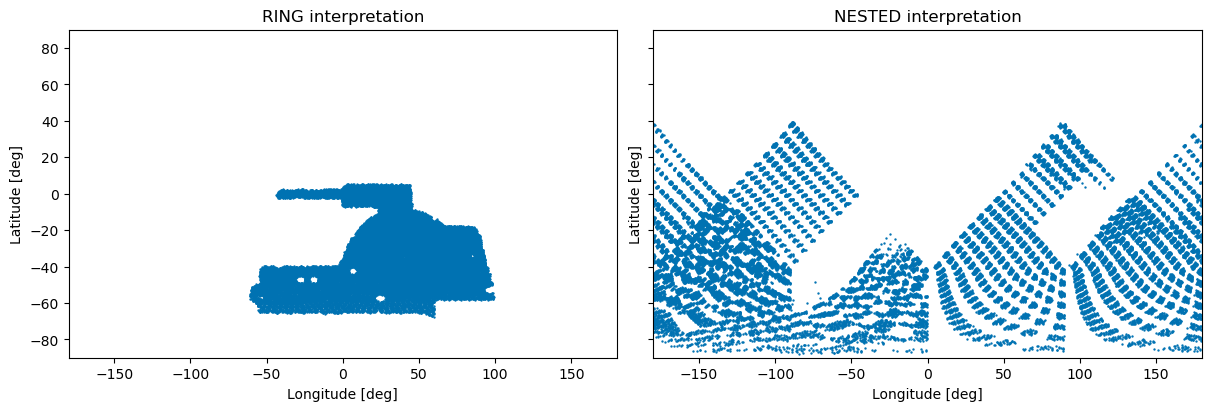

In [3]:
HEALPix = None
try:
    from astropy_healpix import HEALPix
except ImportError:
    print("Install the optional astropy-healpix dependency to recreate the plots.")

if indices is not None and HEALPix is not None:
    positions = np.linspace(
        start=0,
        stop=indices.size - 1,
        num=min(30000, indices.size),
        dtype=int,
    )
    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(12, 4),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )
    # Both conventions accept these integers; only their sky locations differ.
    # A full coordinate comparison reads a small index file, not the map archive.
    for ax, candidate in zip(axes, ["ring", "nested"]):
        longitude, latitude = HEALPix(
            nside=nside,
            order=candidate,
        ).healpix_to_lonlat(indices[positions])
        # Wrap the longitude axis so the DES region crosses zero continuously.
        x = (longitude.deg + 180.0) % 360.0 - 180.0
        ax.scatter(
            x=x,
            y=latitude.deg,
            s=0.5,
            color="#0072B2",
            rasterized=True,
        )
        ax.set(
            title=candidate.upper() + " interpretation",
            xlabel="Longitude [deg]",
            ylabel="Latitude [deg]",
            xlim=(-180, 180),
            ylim=(-90, 90),
        )
    plt.show()

## Plot the footprint and two shear maps

The plot uses at most 30,000 retained positions to keep the preview quick.
This is a display choice, not a thinning rule for science measurements.
The panels share a symmetric color range, so colors have the same meaning
for both realizations. Values beyond the displayed 99th percentile saturate
the colors; the data are unchanged. A gap in this scatter preview need not
be a hole in the complete mask.

The array slots are labeled “component 0/1” until their physical signs and
basis are confirmed. Use the producer's convention when constructing a
TreeCorr catalog; a visually plausible map cannot validate that choice.

RING and the equatorial frame are inferred from the footprint comparison above.

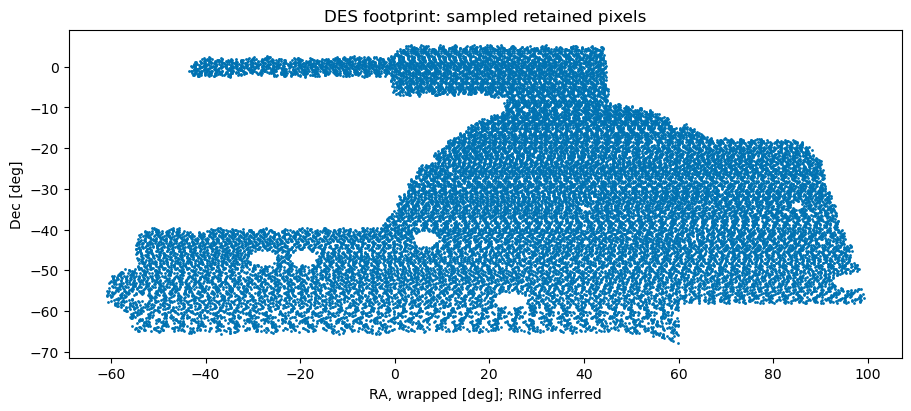

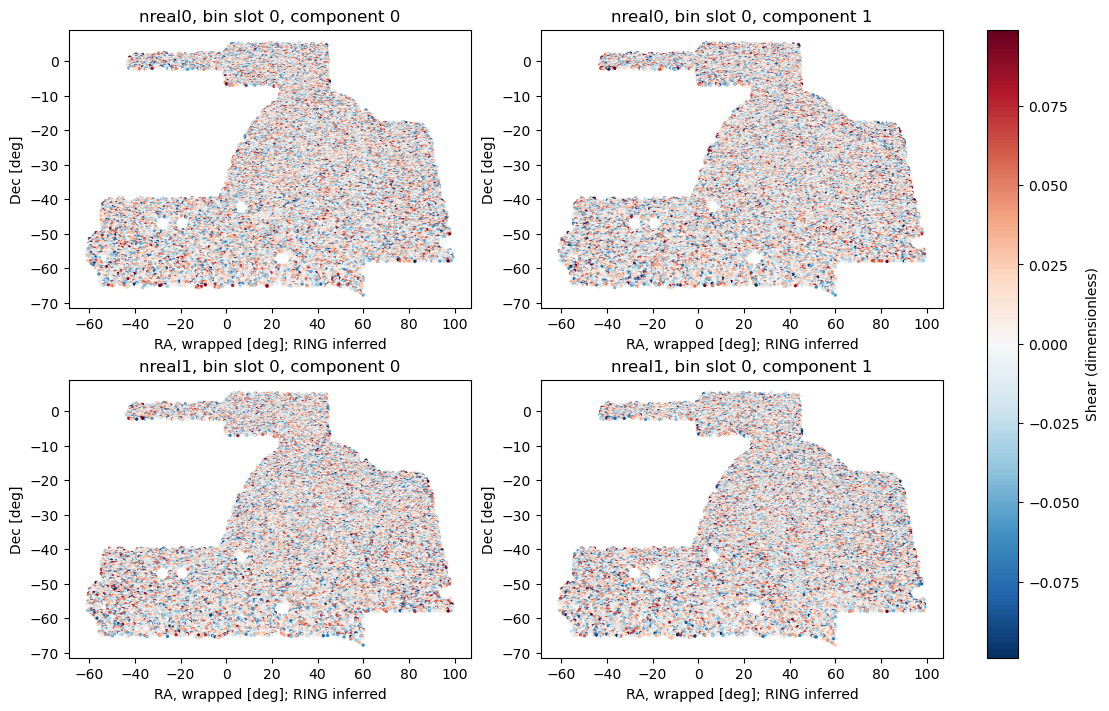

In [4]:
if indices is None or HEALPix is None:
    print("Plot pending: supply indices_512.npy and the coordinate dependency.")
else:
    # Read two small slices, never all maps in the directory.
    positions = np.linspace(
        start=0,
        stop=indices.size - 1,
        num=min(30000, indices.size),
        dtype=int,
    )
    longitude, latitude = HEALPix(
        nside=nside,
        order=ordering,
    ).healpix_to_lonlat(indices[positions])
    longitude = (longitude.deg + 180.0) % 360.0 - 180.0
    latitude = latitude.deg
    xlabel = "RA, wrapped [deg]; RING inferred"
    ylabel = "Dec [deg]"
    fig, ax = plt.subplots(
        figsize=(9, 4),
        constrained_layout=True,
    )
    ax.scatter(
        x=longitude,
        y=latitude,
        s=1,
        color="#0072B2",
        rasterized=True,
    )
    ax.set(
        xlabel=xlabel,
        ylabel=ylabel,
        title="DES footprint: sampled retained pixels",
    )
    plt.show()

    # Select the same positions in both map files. The resulting small array
    # has axes [realization, component, displayed pixel]. It is not a
    # measured correlation vector and must not be fed to the PME routine.
    values = np.stack([shear[source_bin][:, positions] for shear in maps])
    # Use one symmetric color scale for all panels. Rare large amplitudes
    # saturate at the display limit; no values in the source maps are changed.
    limit = np.quantile(np.abs(values), 0.99)
    fig, axes = plt.subplots(
        nrows=2,
        ncols=2,
        figsize=(11, 7),
        constrained_layout=True,
    )
    # Rows compare the two named realizations; columns show component slots.
    # These scalar color plots do not rotate the spin-2 shear basis and do
    # not establish the sign convention needed by a correlation estimator.
    for realization in range(2):
        for component in range(2):
            ax = axes[realization, component]
            points = ax.scatter(
                longitude,
                latitude,
                c=values[realization, component],
                s=2,
                cmap="RdBu_r",
                vmin=-limit,
                vmax=limit,
                rasterized=True,
            )
            ax.set(
                xlabel=xlabel,
                ylabel=ylabel,
                title=f"nreal{realization}, bin slot {source_bin}, component {component}",
            )
    fig.colorbar(
        mappable=points,
        ax=axes.ravel().tolist(),
        label="Shear (dimensionless)",
    )
    plt.show()

## What these pictures establish

They let us inspect the footprint and compare shear values at the same sky
positions. They do **not** show that the two files contain independent
large-scale structure, that the signs match the correlation estimator, or
that NSIDE 512 resolves the smallest aperture used in the analysis.

Proceed to the [covariance notebook](../EXAMPLE_COVARIANCE_PME.ipynb) for
the difference between a map, a measured joint vector and an independent
simulation. Generated plots and vectors belong in `../chains/`; the
simulation files stay out of Git.